<a href="https://colab.research.google.com/github/WahyuFairuzD/Machine-Learning/blob/main/Jobsheet10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
!pip install tensorflow

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [36]:
from google.colab import files

uploaded = files.upload()

Saving Churn_Modelling (1).csv to Churn_Modelling (1) (1).csv


In [37]:
dataset = pd.read_csv('Churn_Modelling (1).csv')

X = dataset.iloc[:, 3:-1].values
y = dataset.iloc[:, -1].values

In [38]:
print(X)

[[619 'France' 'Female' ... 1 1 101348.88]
 [608 'Spain' 'Female' ... 0 1 112542.58]
 [502 'France' 'Female' ... 1 0 113931.57]
 ...
 [709 'France' 'Female' ... 0 1 42085.58]
 [772 'Germany' 'Male' ... 1 0 92888.52]
 [792 'France' 'Female' ... 1 0 38190.78]]


In [39]:
	from sklearn.preprocessing import LabelEncoder
	le = LabelEncoder()
	X[:, 2] = le.fit_transform(X[:, 2])

In [40]:
	from sklearn.compose import ColumnTransformer
	from sklearn.preprocessing import OneHotEncoder
	ct = ColumnTransformer(transformers=[('encoder', OneHotEncoder(), [1])], remainder='passthrough')
	X = np.array(ct.fit_transform(X))

In [41]:
	from sklearn.model_selection import train_test_split
	X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

In [42]:
ann = tf.keras.models.Sequential()

In [43]:
ann.add(tf.keras.layers.Dense(units=6, activation='relu'))

In [44]:
ann.add(tf.keras.layers.Dense(units=6, activation='relu'))

In [45]:
ann.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

In [46]:
ann.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

In [47]:
print("X_train dtype:", X_train.dtype)
print("X_train shape:", X_train.shape)
print(X_train[:5])

X_train dtype: object
X_train shape: (8000, 12)
[[0.0 0.0 1.0 667 0 34 5 0.0 2 1 0 163830.64]
 [0.0 1.0 0.0 427 1 42 1 75681.52 1 1 1 57098.0]
 [1.0 0.0 0.0 535 0 29 2 112367.34 1 1 0 185630.76]
 [0.0 0.0 1.0 654 1 40 5 105683.63 1 1 0 173617.09]
 [0.0 0.0 1.0 850 0 57 8 126776.3 2 1 1 132298.49]]


In [48]:
X_train = np.asarray(X_train, dtype=np.float32)
X_test = np.asarray(X_test, dtype=np.float32)

y_train = np.asarray(y_train, dtype=np.float32)
y_test = np.asarray(y_test, dtype=np.float32)

In [49]:
print("X_train:", X_train.dtype)
print("X_test:", X_test.dtype)
print("y_train:", y_train.dtype)

X_train: float32
X_test: float32
y_train: float32


In [50]:
ann.fit(X_train, y_train, batch_size=32, epochs=100)

Epoch 1/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6639 - loss: 4045.2273
Epoch 2/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7241 - loss: 567.4500
Epoch 3/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7304 - loss: 339.2530
Epoch 4/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7293 - loss: 192.6262
Epoch 5/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7296 - loss: 100.8612
Epoch 6/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7218 - loss: 49.0449
Epoch 7/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6930 - loss: 26.1854
Epoch 8/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6902 - loss: 29.7742
Epoch 9/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6867 - loss: 26.5299
Epoch 10/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6755 - loss: 29.9082
Epoch 11/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6810 - loss: 19.3399
Epoch 12/100
250/250 ━━━

In [51]:
print(dataset['Geography'].unique())

['France' 'Spain' 'Germany']


In [52]:
print(ann.predict(sc.transform([[1, 0, 0, 600, 1, 40, 3, 60000, 2, 1, 1, 50000]])) > 0.5)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
[[False]]


In [53]:
	y_pred = ann.predict(X_test)
	y_pred = (y_pred > 0.5)
	print(np.concatenate((y_pred.reshape(len(y_pred),1), y_test.reshape(len(y_test),1)),1))

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
[[0. 0.]
 [0. 1.]
 [0. 0.]
 ...
 [0. 0.]
 [0. 0.]
 [0. 0.]]


In [54]:
	from sklearn.metrics import confusion_matrix, accuracy_score
	cm = confusion_matrix(y_test, y_pred)
	print(cm)
	accuracy_score(y_test, y_pred)

[[1569   26]
 [ 386   19]]


0.794

Lab 4 Day and Malang Classification with ANN

In [55]:
	from pathlib import Path
	import numpy as np
	import matplotlib.pyplot as plt
	import cv2

	from skimage.feature import hog
	from sklearn.preprocessing import StandardScaler
	from sklearn.model_selection import train_test_split
	from sklearn.metrics import confusion_matrix, classification_report

	import tensorflow as tf
	from tensorflow.keras import layers, models

In [56]:
	# Load images and labels from a directory structure
	def load_dataset(img_dir):
	    p = Path(img_dir)
	    img_list = []
	    for folder in p.glob('*'):
	        label = folder.name
	        for file in folder.glob('*.jpg'):
	            img = cv2.imread(str(file))
	            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
	            img_list.append((img, label))
	    return img_list

	train_dir = "images/training/"
	test_dir  = "images/test/"

	train_img = load_dataset(train_dir)
	test_img  = load_dataset(test_dir)

In [57]:
	# Preprocess images: resize and encode labels
	def resize_image(img, size=(256,256)):
	    return cv2.resize(img, size)

	def label_encoder(label):
	    return 1 if label == 'day' else 0

	def preprocess(img_list):
	    X = []
	    y = []
	    for img, label in img_list:
	        img_std = resize_image(img)
	        X.append(img_std)
	        y.append(label_encoder(label))
	    return X, y

	X_train_img, y_train = preprocess(train_img)
	X_test_img,  y_test  = preprocess(test_img)

In [58]:
	# Extract HOG features
	def extract_hog(X_imgs):
	    feats = []
	    for img in X_imgs:
	        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
	        hog_feat = hog(gray,
	                       orientations=9,
	                       pixels_per_cell=(8,8),
	                       cells_per_block=(2,2),
	                       block_norm='L2-Hys',
	                       visualize=False,
	                       feature_vector=True)
	        feats.append(hog_feat)
	    return np.array(feats)

	X_train_feat = extract_hog(X_train_img)
	X_test_feat  = extract_hog(X_test_img)

In [63]:
from sklearn.preprocessing import StandardScaler

# Gunakan data training dan testing yang sudah tersedia
X_train_feat = X_train
X_test_feat = X_test

# Normalize features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled = scaler.transform(X_test_feat)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (8000, 12)
X_test_scaled shape: (2000, 12)


In [65]:
	input_dim = X_train.shape[1]

	model = models.Sequential([
	    layers.Input(shape=(input_dim,)),
	    layers.Dense(128, activation='relu'),
	    layers.Dense(64, activation='relu'),
	    layers.Dense(1, activation='sigmoid')
	])

	model.compile(
	    optimizer='adam',
	    loss='binary_crossentropy',
	    metrics=['accuracy']
	)

	model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 128)            │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,985 (39.00 KB)

 Trainable params: 9,985 (39.00 KB)

 Non-trainable params: 0 (0.00 B)

In [76]:
history = ann.fit(
    X_train_scaled,
    y_train,
    batch_size=32,
    epochs=100,
    validation_data=(X_test_scaled, y_test)
)

Epoch 1/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8294 - loss: 0.4004 - val_accuracy: 0.8305 - val_loss: 0.4053
Epoch 2/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8314 - loss: 0.4001 - val_accuracy: 0.8305 - val_loss: 0.4051
Epoch 3/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8311 - loss: 0.3995 - val_accuracy: 0.8315 - val_loss: 0.4030
Epoch 4/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8328 - loss: 0.3993 - val_accuracy: 0.8330 - val_loss: 0.4040
Epoch 5/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8306 - loss: 0.3989 - val_accuracy: 0.8315 - val_loss: 0.4029
Epoch 6/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8320 - loss: 0.3988 - val_accuracy: 0.8315 - val_loss: 0.4023
Epoch 7/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8295 - loss: 0.3979 - val_accuracy: 0.8290 - val_loss: 0.4020
Epoch 8/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8306 - loss: 0.3985 - val_accu

In [78]:
	test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
	print("Test Accuracy:", test_acc)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2520 - loss: 0.7868
Test Accuracy: 0.25200000405311584


In [79]:
	y_pred_prob = model.predict(X_test_scaled)
	y_pred = (y_pred_prob > 0.5).astype(int)

	print(classification_report(y_test, y_pred))
	print(confusion_matrix(y_test, y_pred))

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
              precision    recall  f1-score   support

         0.0       0.77      0.09      0.16      1595
         1.0       0.20      0.89      0.33       405

    accuracy                           0.25      2000
   macro avg       0.48      0.49      0.24      2000
weighted avg       0.65      0.25      0.19      2000

[[ 142 1453]
 [  43  362]]


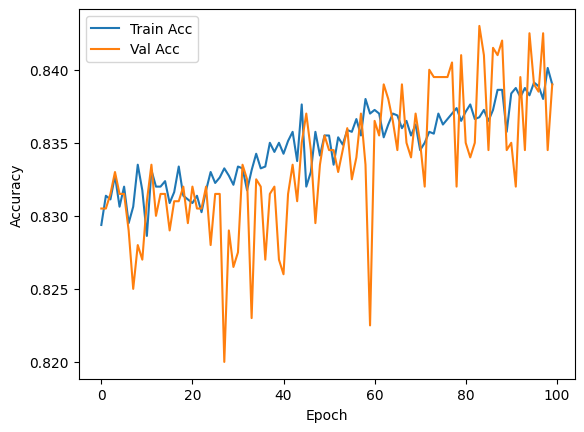

In [80]:
	plt.plot(history.history['accuracy'], label='Train Acc')
	plt.plot(history.history['val_accuracy'], label='Val Acc')
	plt.xlabel('Epoch')
	plt.ylabel('Accuracy')
	plt.legend()
	plt.show()

In [81]:
model.save('day_night_classifier_model.h5')

ASSIGNMENT

In [82]:
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.utils import to_categorical

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [83]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train: (60000, 28, 28)
y_train: (60000,)
X_test: (10000, 28, 28)
y_test: (10000,)


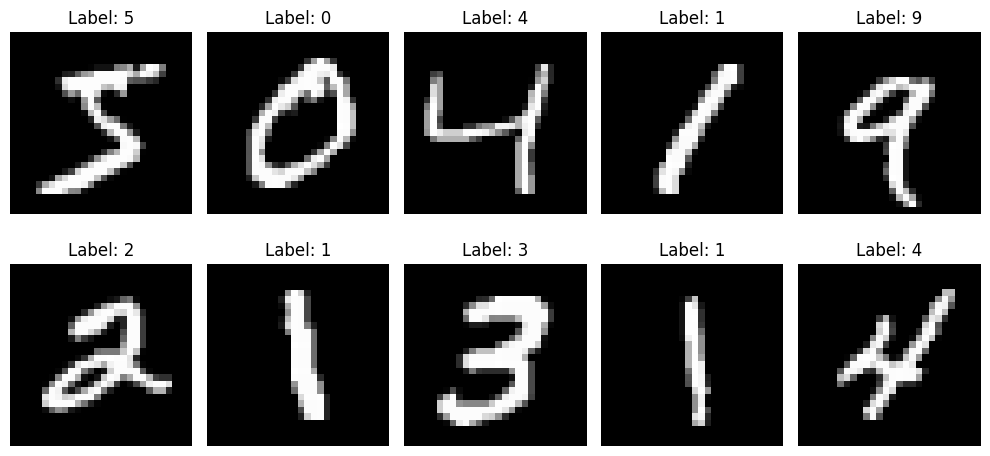

In [84]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [85]:
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print("Nilai minimum:", X_train.min())
print("Nilai maksimum:", X_train.max())

Nilai minimum: 0.0
Nilai maksimum: 1.0


In [86]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Jumlah kelas:", len(np.unique(y_train)))
print("Label:", np.unique(y_train))

X_train shape: (60000, 28, 28)
X_test shape: (10000, 28, 28)
Jumlah kelas: 10
Label: [0 1 2 3 4 5 6 7 8 9]


In [87]:
ann = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

ann.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [88]:
ann.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [89]:
history = ann.fit(
    X_train,
    y_train,
    batch_size=32,
    epochs=20,
    validation_data=(X_test, y_test)
)

Epoch 1/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 9ms/step - accuracy: 0.9306 - loss: 0.2366 - val_accuracy: 0.9650 - val_loss: 0.1140
Epoch 2/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.9688 - loss: 0.1031 - val_accuracy: 0.9639 - val_loss: 0.1160
Epoch 3/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.9773 - loss: 0.0715 - val_accuracy: 0.9754 - val_loss: 0.0805
Epoch 4/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 28s 12ms/step - accuracy: 0.9827 - loss: 0.0556 - val_accuracy: 0.9746 - val_loss: 0.0821
Epoch 5/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 22s 12ms/step - accuracy: 0.9861 - loss: 0.0429 - val_accuracy: 0.9763 - val_loss: 0.0838
Epoch 6/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 30s 6ms/step - accuracy: 0.9891 - loss: 0.0338 - val_accuracy: 0.9770 - val_loss: 0.0849
Epoch 7/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9904 - loss: 0.0289 - val_accuracy: 0.9772 - val_loss: 0.0806
Epoch 8/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9914 - loss:

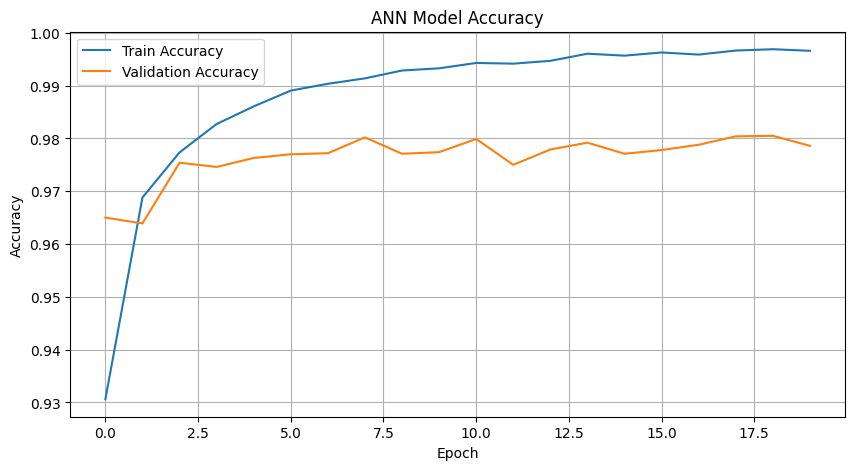

In [90]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('ANN Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

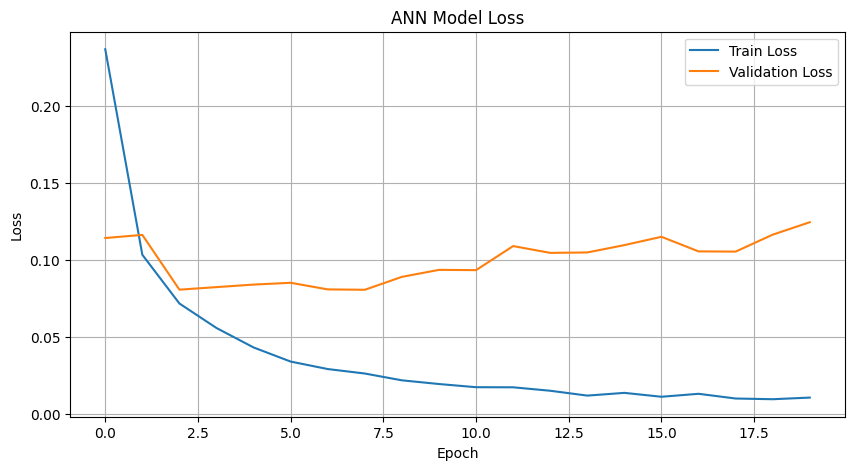

In [91]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('ANN Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

In [92]:
test_loss, test_accuracy = ann.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9786 - loss: 0.1243
Test Loss: 0.12426447868347168
Test Accuracy: 0.978600025177002
Test Accuracy (%): 97.8600025177002


In [93]:
y_pred_prob = ann.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)

print("Prediksi:", y_pred[:10])
print("Label asli:", y_test[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Prediksi: [7 2 1 0 4 1 4 9 5 9]
Label asli: [7 2 1 0 4 1 4 9 5 9]


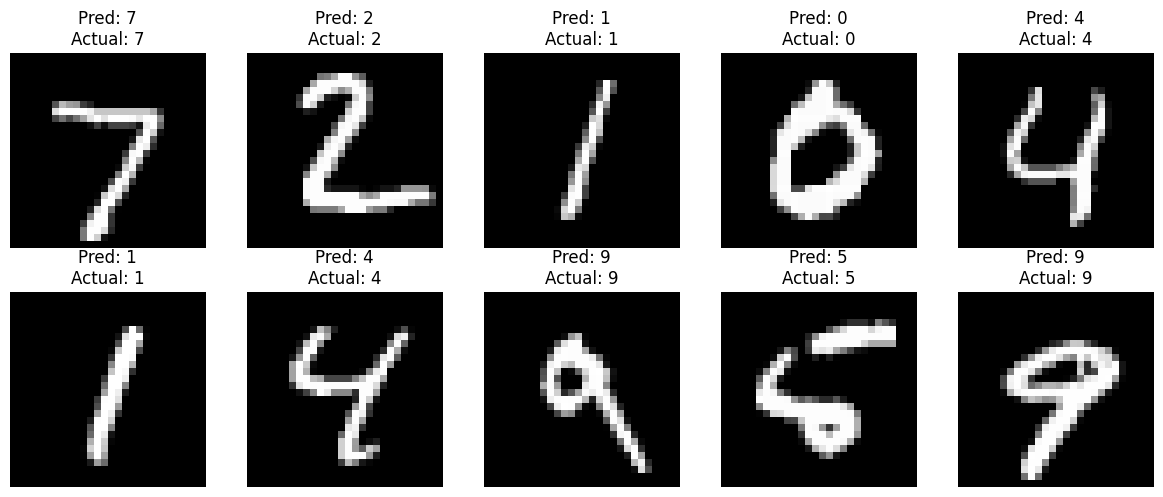

In [94]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i], cmap='gray')

    plt.title(
        f"Pred: {y_pred[i]}\nActual: {y_test[i]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [95]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.98      1.00      0.99      1135
           2       0.98      0.98      0.98      1032
           3       0.98      0.98      0.98      1010
           4       0.98      0.98      0.98       982
           5       0.96      0.98      0.97       892
           6       0.99      0.98      0.98       958
           7       0.98      0.97      0.97      1028
           8       0.98      0.97      0.97       974
           9       0.98      0.96      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



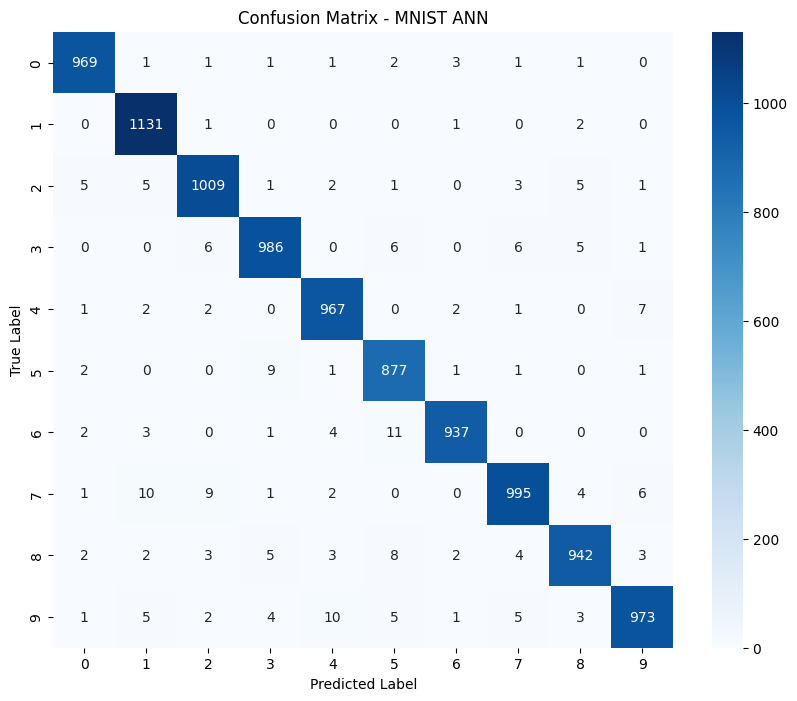

In [96]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Confusion Matrix - MNIST ANN')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

In [97]:
ann_experiment = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

ann_experiment.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_experiment = ann_experiment.fit(
    X_train,
    y_train,
    batch_size=32,
    epochs=20,
    validation_split=0.1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9322 - loss: 0.2241 - val_accuracy: 0.9658 - val_loss: 0.1151
Epoch 2/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9708 - loss: 0.0938 - val_accuracy: 0.9715 - val_loss: 0.0949
Epoch 3/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9785 - loss: 0.0671 - val_accuracy: 0.9722 - val_loss: 0.0994
Epoch 4/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9827 - loss: 0.0518 - val_accuracy: 0.9772 - val_loss: 0.0833
Epoch 5/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9874 - loss: 0.0404 - val_accuracy: 0.9793 - val_loss: 0.0782
Epoch 6/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9879 - loss: 0.0366 - val_accuracy: 0.9810 - val_loss: 0.0796
Epoch 7/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9911 - loss: 0.0288 - val_accuracy: 0.9835 - val_loss: 0.0687
Epoch 8/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9920 - loss: 0.0

In [98]:
experiment_loss, experiment_accuracy = ann_experiment.evaluate(
    X_test,
    y_test
)

print("Experiment Accuracy:", experiment_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9798 - loss: 0.1068
Experiment Accuracy: 97.97999858856201 %


In [99]:
ann_tanh = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='tanh'),
    Dense(64, activation='tanh'),
    Dense(10, activation='softmax')
])

ann_tanh.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_tanh = ann_tanh.fit(
    X_train,
    y_train,
    batch_size=32,
    epochs=20,
    validation_split=0.1
)

Epoch 1/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9202 - loss: 0.2748 - val_accuracy: 0.9583 - val_loss: 0.1401
Epoch 2/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9614 - loss: 0.1277 - val_accuracy: 0.9725 - val_loss: 0.0956
Epoch 3/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9749 - loss: 0.0845 - val_accuracy: 0.9777 - val_loss: 0.0770
Epoch 4/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9799 - loss: 0.0636 - val_accuracy: 0.9733 - val_loss: 0.0905
Epoch 5/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9863 - loss: 0.0455 - val_accuracy: 0.9768 - val_loss: 0.0808
Epoch 6/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9896 - loss: 0.0355 - val_accuracy: 0.9780 - val_loss: 0.0792
Epoch 7/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9906 - loss: 0.0296 - val_accuracy: 0.9787 - val_loss: 0.0743
Epoch 8/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9934 - loss: 0.0223 - 

In [100]:
tanh_loss, tanh_accuracy = ann_tanh.evaluate(X_test, y_test)

print("Tanh Test Accuracy:", tanh_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9776 - loss: 0.0979
Tanh Test Accuracy: 97.75999784469604 %


## Conclusion

In this lab assignment, an Artificial Neural Network (ANN) was implemented using TensorFlow to classify handwritten digits from the MNIST dataset. The dataset consists of grayscale images representing digits from 0 to 9.

Data preprocessing was performed by normalizing pixel values from 0–255 into a range of 0–1. The ANN model was built using a Flatten layer, two hidden Dense layers with ReLU activation, and an output layer with 10 neurons using Softmax activation.

The model was trained and evaluated using training and testing data. Model performance was analyzed using accuracy, loss, classification report, and confusion matrix. Different ANN architectures and activation functions can also be compared to determine their effect on classification performance.

The experiment demonstrates that ANN can learn patterns from handwritten digit images and perform multiclass classification effectively.